In [ ]:
import os
import requests
import hashlib
import json
from datetime import datetime

# 1. Criar estrutura de pastas para preservar os dados originais (Regra de Ouro do ETL)
os.makedirs('dados/brutos', exist_ok=True)
os.makedirs('dados/tratados', exist_ok=True)
os.makedirs('logs', exist_ok=True)

# 2. Configurações da API CKAN e do Recurso S5 identificado por você
BASE_API = "https://dados.recife.pe.gov.br/api/3/action/"
RESOURCE_ID_S5 = "36c2b47b-f439-4895-8b65-3f3dda36a4a7"  # Lista de Equipamentos de fiscalização de trânsito

print("🔍 Buscando metadados oficiais do recurso S5 na API CKAN...")
response = requests.get(f"{BASE_API}resource_show?id={RESOURCE_ID_S5}", timeout=30)
response.raise_for_status()
metadata = response.json()["result"]
download_url = metadata["url"]

print(f"📥 Baixando arquivo bruto de: {download_url}")
file_content = requests.get(download_url, timeout=60).content

# 3. Salvar o arquivo BRUTO (Este arquivo NUNCA será alterado ou sobrescrito)
raw_file_path = "dados/brutos/equipamentos_s5_bruto.csv"
with open(raw_file_path, "wb") as f:
    f.write(file_content)

# 4. Gerar Hash SHA256 para garantir a rastreabilidade e integridade do arquivo
sha256_hash = hashlib.sha256(file_content).hexdigest()

# 5. Criar e salvar o log de extração (Exigência do enunciado: catálogo e logs de coleta)
log_extracao = {
    "etl": "S5_Equipamentos_Fiscalizacao",
    "resource_id": RESOURCE_ID_S5,
    "nome_recurso": metadata["name"],
    "url_origem": download_url,
    "arquivo_bruto_salvo": raw_file_path,
    "sha256": sha256_hash,
    "data_hora_extracao": datetime.now().isoformat()
}

with open("logs/extracao_s5.json", "w", encoding="utf-8") as f:
    json.dump(log_extracao, f, indent=4, ensure_ascii=False)

print("✅ Sucesso! Arquivo bruto salvo e log de extração gerado.")
print(f"📊 Tamanho do arquivo baixado: {len(file_content) / 1024:.2f} KB")

🔍 Buscando metadados oficiais do recurso S5 na API CKAN...
📥 Baixando arquivo bruto de: https://dados.recife.pe.gov.br:443/dataset/9acffb30-ed06-4b16-84ff-710478f18760/resource/36c2b47b-f439-4895-8b65-3f3dda36a4a7/download/lista-de-equipamentos-de-fiscalizacao-de-transito.csv
✅ Sucesso! Arquivo bruto salvo e log de extração gerado.
📊 Tamanho do arquivo baixado: 13.73 KB


In [ ]:
import pandas as pd
import numpy as np

# 1. Carregar o arquivo BRUTO (lendo tudo como string inicialmente para não perder formatação, ex: zeros à esquerda)
caminho_bruto = "dados/brutos/equipamentos_s5_bruto.csv"
df_raw = pd.read_csv(caminho_bruto, dtype=str, encoding="utf-8")

print("="*50)
print("📊 INSPEÇÃO INICIAL DOS DADOS (S5 - BRUTO)")
print("="*50)

# 2. Dimensões do dataset
print(f"\n1. Dimensões: {df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas.")

# 3. Nomes das colunas
print(f"\n2. Colunas encontradas:\n{df_raw.columns.tolist()}")

# 4. Amostra dos primeiros registros
print("\n3. Primeiras 5 linhas:")
display(df_raw.head())

# 5. Contagem de valores nulos/ausentes por coluna
print("\n4. Valores nulos (NaN) por coluna:")
print(df_raw.isna().sum())

# 6. Contagem de duplicatas exatas (linhas completamente idênticas)
print(f"\n5. Linhas duplicadas (exatas): {df_raw.duplicated().sum()}")

# 7. Investigação específica dos campos-chave do enunciado
print("\n6. Análise rápida dos campos-chave:")
print(f"   - Valores únicos em 'tipo_equipamento': {df_raw['tipo_equipamento'].nunique() if 'tipo_equipamento' in df_raw.columns else 'Coluna não encontrada'}")
print(f"   - Valores únicos em 'identificacao_equipamento': {df_raw['identificacao_equipamento'].nunique() if 'identificacao_equipamento' in df_raw.columns else 'Coluna não encontrada'}")

# Verificar se latitude e longitude existem e quantas têm valor
if 'latitude' in df_raw.columns and 'longitude' in df_raw.columns:
    lat_nulos = df_raw['latitude'].isna().sum() + (df_raw['latitude'] == '').sum()
    lon_nulos = df_raw['longitude'].isna().sum() + (df_raw['longitude'] == '').sum()
    print(f"   - Registros sem latitude: {lat_nulos}")
    print(f"   - Registros sem longitude: {lon_nulos}")
else:
    print("   ⚠️ Colunas 'latitude' e/ou 'longitude' não encontradas com esses nomes exatos.")

📊 INSPEÇÃO INICIAL DOS DADOS (S5 - BRUTO)

1. Dimensões: 87 linhas e 1 colunas.

2. Colunas encontradas:
['tipo_equipamento;"registro_inmetro";"numero_serie_fabricante";"identificacao_equipamento";"local_instalacao";"sentido_fiscalizacao";"latitude";"longitude";"faixas_fiscalizadas";"velocidade_fiscalizada";"vmd";"periodo_vmd"']

3. Primeiras 5 linhas:


,"tipo_equipamento;""registro_inmetro"";""numero_serie_fabricante"";""identificacao_equipamento"";""local_instalacao"";""sentido_fiscalizacao"";""latitude"";""longitude"";""faixas_fiscalizadas"";""velocidade_fiscalizada"";""vmd"";""periodo_vmd"""
"FIXO;""Portaria 018/2018-243/2022"";""R13727"";""9111"";""AV. GENERAL SAN MARTIN","N. 1864"";""DOIS SENTIDOS"";""-8.067404"";""-34.927..."
"FIXO;""Portaria 018/2018-243/2022"";""R14646"";""9438"";""AV. DOM JOAO VI","PROXIMO AO SEMAFORO 669"";""SUBURBIO"";""-8.11571..."
"FIXO;""Portaria 018/2018-243/2022"";""R14647"";""9439"";""AV. ENG. JOS ESTELITA","APàS PTE. AGAMENON MAGALHAES"";""DERBY"";""-8.080..."
"FIXO;""Portaria 018/2018-243/2022"";""R14655"";""9440"";""AV. ENG. JOS ESTELITA","APàS PTE. AGAMENON MAGALHAES"";""DERBY"";""-8.080..."
"FIXO;""Portaria 018/2018-243/2022"";""R14643"";""9442"";""AV. BOA VIAGEM","ENTRE O N. 2080 E 1906"";""-"";""-8.1078431"";""-34..."



4. Valores nulos (NaN) por coluna:
tipo_equipamento;"registro_inmetro";"numero_serie_fabricante";"identificacao_equipamento";"local_instalacao";"sentido_fiscalizacao";"latitude";"longitude";"faixas_fiscalizadas";"velocidade_fiscalizada";"vmd";"periodo_vmd"    2
dtype: int64

5. Linhas duplicadas (exatas): 1

6. Análise rápida dos campos-chave:
   - Valores únicos em 'tipo_equipamento': Coluna não encontrada
   - Valores únicos em 'identificacao_equipamento': Coluna não encontrada
   ⚠️ Colunas 'latitude' e/ou 'longitude' não encontradas com esses nomes exatos.


In [ ]:
import pandas as pd
import numpy as np

# ============================================================
# PASSO 3 — LIMPEZA E VALIDAÇÃO (com separador ';' corrigido)
# ============================================================

# 1. Carregar o bruto em uma cópia de trabalho, usando o separador correto
caminho_bruto = "dados/brutos/equipamentos_s5_bruto.csv"
df_raw = pd.read_csv(caminho_bruto, sep=';', dtype=str, encoding="utf-8")
df = df_raw.copy()

# Lista para registrar o histórico de transformações (exigência do enunciado)
historico = []

# ------------------------------------------------------------
# 3.1 Padronização dos nomes das colunas (snake_case, minúsculo)
# ------------------------------------------------------------
df.columns = [c.strip().lower().replace(" ", "_").replace("-", "_") for c in df.columns]
historico.append({
    "ordem": 1,
    "variavel": "todas as colunas",
    "problema": "nomes com espaços, maiúsculas ou hífens",
    "acao": "padronização para snake_case minúsculo",
    "justificativa": "facilita acesso programático e evita erros de digitação",
    "impacto": f"{len(df.columns)} colunas renomeadas"
})

# ------------------------------------------------------------
# 3.2 Tratamento do identificador do equipamento
# ------------------------------------------------------------
if "identificacao_equipamento" in df.columns:
    df["id_equipamento"] = df["identificacao_equipamento"].astype(str).str.strip()
    df.loc[df["id_equipamento"].str.lower().isin(["", "nan", "none", "null"]), "id_equipamento"] = np.nan
    qtd_sem_id = df["id_equipamento"].isna().sum()
    historico.append({
        "ordem": 2,
        "variavel": "identificacao_equipamento",
        "problema": "valores vazios, 'nan' ou espaços",
        "acao": "criação de id_equipamento limpo + conversão de vazios para NaN",
        "justificativa": "garante identificador textual estável para auditoria",
        "impacto": f"{qtd_sem_id} registros sem identificador válido"
    })

# ------------------------------------------------------------
# 3.3 Padronização do tipo de equipamento
# ------------------------------------------------------------
if "tipo_equipamento" in df.columns:
    df["tipo_equipamento"] = df["tipo_equipamento"].astype(str).str.strip().str.title()
    df.loc[df["tipo_equipamento"].str.lower().isin(["", "nan", "none"]), "tipo_equipamento"] = np.nan
    historico.append({
        "ordem": 3,
        "variavel": "tipo_equipamento",
        "problema": "grafias variadas (maiúsculas/minúsculas)",
        "acao": "padronização com .title()",
        "justificativa": "uniformiza categorias para agregação",
        "impacto": f"{df['tipo_equipamento'].nunique()} tipos únicos após padronização"
    })

# ------------------------------------------------------------
# 3.4 Conversão de latitude e longitude para numérico
# ------------------------------------------------------------
if "latitude" in df.columns and "longitude" in df.columns:
    # Substituir vírgula por ponto (padrão brasileiro) e converter para float
    df["latitude"]  = pd.to_numeric(df["latitude"].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    df["longitude"] = pd.to_numeric(df["longitude"].astype(str).str.replace(",", ".", regex=False), errors="coerce")

    # Bbox aproximada do Recife (filtro de coordenadas grosseiramente inválidas)
    mask_bbox = (
        df["latitude"].between(-8.20, -7.90) &
        df["longitude"].between(-35.10, -34.85)
    )
    df["coord_valida"] = df["latitude"].notna() & df["longitude"].notna() & mask_bbox

    qtd_lat_nulas = df["latitude"].isna().sum()
    qtd_lon_nulas = df["longitude"].isna().sum()
    qtd_fora_bbox = (df["latitude"].notna() & df["longitude"].notna() & ~mask_bbox).sum()

    historico.append({
        "ordem": 4,
        "variavel": "latitude e longitude",
        "problema": "vírgula decimal, nulos e coordenadas fora do Recife",
        "acao": "conversão para float + validação por bounding box do Recife",
        "justificativa": "garante que apenas pontos dentro do município sejam usados no join espacial",
        "impacto": f"{qtd_lat_nulas} lat nulas | {qtd_lon_nulas} lon nulas | {qtd_fora_bbox} fora da bbox | {df['coord_valida'].sum()} válidas"
    })

# ------------------------------------------------------------
# 3.5 Sinalização de possíveis duplicatas (SEM remover)
# ------------------------------------------------------------
if "id_equipamento" in df.columns:
    df["repetido_id"] = df.duplicated(subset=["id_equipamento"], keep=False)
    qtd_repetidos = df["repetido_id"].sum()
    historico.append({
        "ordem": 5,
        "variavel": "id_equipamento",
        "problema": "possíveis repetições de identificador",
        "acao": "flag 'repetido_id' criada (sem remoção)",
        "justificativa": "preserva dados para auditoria; remoção só com critério explícito",
        "impacto": f"{qtd_repetidos} linhas marcadas como repetidas"
    })

# ------------------------------------------------------------
# 3.6 Tratamento do local de instalação
# ------------------------------------------------------------
if "local_instalacao" in df.columns:
    df["local_instalacao"] = df["local_instalacao"].astype(str).str.strip()
    df.loc[df["local_instalacao"].str.lower().isin(["", "nan", "none"]), "local_instalacao"] = np.nan
    qtd_local_nulo = df["local_instalacao"].isna().sum()
    historico.append({
        "ordem": 6,
        "variavel": "local_instalacao",
        "problema": "valores vazios ou 'nan'",
        "acao": "limpeza de espaços e conversão para NaN",
        "justificativa": "padroniza campo textual para análises e mapas",
        "impacto": f"{qtd_local_nulo} registros sem local informado"
    })

# ------------------------------------------------------------
# 3.7 Salvar histórico de transformações
# ------------------------------------------------------------
df_historico = pd.DataFrame(historico)
df_historico.to_csv("logs/historico_transformacoes_s5.csv", index=False, encoding="utf-8")

# ------------------------------------------------------------
# 3.8 Resumo final da limpeza
# ------------------------------------------------------------
print("="*60)
print("✅ PASSO 3 CONCLUÍDO — LIMPEZA E VALIDAÇÃO")
print("="*60)
print(f"\n📊 Shape após limpeza: {df.shape[0]} linhas × {df.shape[1]} colunas")
print(f"\n📍 Coordenadas válidas (dentro do Recife): {df['coord_valida'].sum()} / {len(df)}")
print(f"   Percentual sem geolocalização válida: {(1 - df['coord_valida'].mean()) * 100:.2f}%")
print(f"\n🔧 Tipos de equipamento únicos: {df['tipo_equipamento'].nunique()}")
print(f"🆔 Registros sem identificador: {df['id_equipamento'].isna().sum()}")
print(f"\n📜 Histórico salvo em: logs/historico_transformacoes_s5.csv")
print("\nPré-visualização das colunas tratadas:")
display(df[["id_equipamento", "tipo_equipamento", "local_instalacao", "latitude", "longitude", "coord_valida"]].head())

# ------------------------------------------------------------
# 3.9 Salvar o DataFrame tratado (Essencial para o Bloco 4)
# ------------------------------------------------------------
os.makedirs("dados/tratados", exist_ok=True)
df.to_csv("dados/tratados/equipamentos_s5_tratado.csv", index=False, encoding="utf-8")
print("💾 DataFrame tratado salvo em: dados/tratados/equipamentos_s5_tratado.csv")

✅ PASSO 3 CONCLUÍDO — LIMPEZA E VALIDAÇÃO

📊 Shape após limpeza: 87 linhas × 15 colunas

📍 Coordenadas válidas (dentro do Recife): 87 / 87
   Percentual sem geolocalização válida: 0.00%

🔧 Tipos de equipamento únicos: 1
🆔 Registros sem identificador: 0

📜 Histórico salvo em: logs/historico_transformacoes_s5.csv

Pré-visualização das colunas tratadas:


,id_equipamento,tipo_equipamento,local_instalacao,latitude,longitude,coord_valida
0,9111,Fixo,"AV. GENERAL SAN MARTIN, N. 1864",-8.067404,-34.927845,True
1,9438,Fixo,"AV. DOM JOAO VI, PROXIMO AO SEMAFORO 669",-8.115720,-34.904324,True
2,9439,Fixo,"AV. ENG. JOS ESTELITA, APàS PTE. AGAMENON MAG...",-8.080763,-34.891213,True
3,9440,Fixo,"AV. ENG. JOS ESTELITA, APàS PTE. AGAMENON MAG...",-8.080763,-34.891213,True
4,9442,Fixo,"AV. BOA VIAGEM, ENTRE O N. 2080 E 1906",-8.107843,-34.888161,True


💾 DataFrame tratado salvo em: dados/tratados/equipamentos_s5_tratado.csv


In [ ]:
# ==============================================================================
# BLOCO 4: INTEGRAÇÃO ESPACIAL DEFINITIVA (Correção de Geometria e Coluna)
# ==============================================================================
import geopandas as gpd
import pandas as pd
import os
import requests

print("🔄 Executando integração espacial definitiva...")

# 1. Carregar dados tratados
caminho_tratado = "dados/tratados/equipamentos_s5_tratado.csv"
if not os.path.exists(caminho_tratado):
    raise FileNotFoundError(f"Arquivo {caminho_tratado} não encontrado. Execute o Bloco 3 primeiro.")

df_validos = pd.read_csv(caminho_tratado)
df_validos = df_validos[df_validos["coord_valida"]].copy()

# 2. Carregar ou baixar bairros (S6)
caminho_bairros = "dados/brutos/bairros_recife_s6.geojson"
os.makedirs("dados/brutos", exist_ok=True)

if not os.path.exists(caminho_bairros):
    print("⚠️ GeoJSON dos bairros não encontrado. Baixando do S6...")
    url_s6 = "https://dados.recife.pe.gov.br/dataset/ce23d3f4-7474-44d3-b310-19f3afcebf4a/resource/d5f956ce-7e1f-4c74-839b-06cb490c3721/download/limites-dos-bairros-2023.geojson"
    resp = requests.get(url_s6, timeout=60)
    resp.raise_for_status()
    with open(caminho_bairros, "wb") as f:
        f.write(resp.content)

bairros = gpd.read_file(caminho_bairros)

# 🔧 CORREÇÃO 1: Garantir CRS e REPARAR geometrias inválidas
if bairros.crs is None:
    bairros = bairros.set_crs(epsg=4326)

# O "buffer(0)" é um truque essencial para corrigir polígonos com erros de topologia
# Sem isso, o sjoin frequentemente retorna NaN para todos os pontos.
bairros.geometry = bairros.geometry.buffer(0)

# 3. Criar GeoDataFrame dos equipamentos (EPSG:4326)
equipamentos_gdf = gpd.GeoDataFrame(
    df_validos,
    geometry=gpd.points_from_xy(df_validos["longitude"], df_validos["latitude"]),
    crs="EPSG:4326"
)

# 4. Reprojetar ambos para SIRGAS 2000 / UTM 25S (EPSG:31985)
bairros_utm = bairros.to_crs("EPSG:31985")
equipamentos_utm = equipamentos_gdf.to_crs("EPSG:31985")

# 5. Spatial Join (usando 'within' que é semanticamente correto para pontos em polígonos)
print("   🔍 Realizando interseção espacial (sjoin)...")
equipamentos_com_bairro = equipamentos_utm.sjoin(bairros_utm, how="left", predicate="within")

# 🔧 CORREÇÃO 2: Forçar a busca pela coluna oficial de nomes do Recife
# Priorizamos EBAIRRNOMEOF, depois EBAIRRNOME, e evitamos colunas de ID
colunas_oficiais = ['EBAIRRNOMEOF', 'EBAIRRNOME', 'NOME', 'bairro']
colunas_possiveis = [col for col in equipamentos_com_bairro.columns if col in colunas_oficiais]

# Fallback: busca parcial excluindo IDs
if not colunas_possiveis:
    colunas_possiveis = [col for col in equipamentos_com_bairro.columns if 'nome' in col.lower() and 'id' not in col.lower()]

coluna_nome_bairro = colunas_possiveis[0] if colunas_possiveis else None

if coluna_nome_bairro:
    print(f"   📌 Usando coluna oficial: '{coluna_nome_bairro}'")
    nulos_antes = equipamentos_com_bairro[coluna_nome_bairro].isna().sum()
    print(f"   ⚠️ Registros SEM correspondência espacial: {nulos_antes} de {len(equipamentos_com_bairro)}")

    equipamentos_com_bairro["bairro"] = equipamentos_com_bairro[coluna_nome_bairro].astype(str).str.strip().str.title()
    equipamentos_com_bairro.loc[equipamentos_com_bairro["bairro"].str.lower().isin(["", "nan", "none", "null"]), "bairro"] = "NÃO IDENTIFICADO"
else:
    print("   ❌ Nenhuma coluna de nome de bairro encontrada.")
    equipamentos_com_bairro["bairro"] = "NÃO IDENTIFICADO"

# 6. Reprojetar de volta para EPSG:4326 para visualização
equipamentos_final = equipamentos_com_bairro.to_crs("EPSG:4326")

# 7. Salvar o resultado geoespacial tratado
os.makedirs("dados/tratados", exist_ok=True)
arquivo_tratado_geo = "dados/tratados/equipamentos_s5_georreferenciado.geojson"
equipamentos_final.to_file(arquivo_tratado_geo, driver="GeoJSON", encoding="utf-8")

print("="*60)
print("✅ PASSO 4 CONCLUÍDO — INTEGRAÇÃO ESPACIAL")
print("="*60)
print(f"📊 Total de equipamentos com coordenadas válidas: {len(equipamentos_final)}")
com_bairro = (equipamentos_final["bairro"] != "NÃO IDENTIFICADO").sum()
print(f"🏘️ Equipamentos associados a um bairro: {com_bairro}")
print(f"⚠️ Equipamentos sem bairro identificado: {len(equipamentos_final) - com_bairro}")
print(f"💾 Arquivo salvo em: {arquivo_tratado_geo}")

🔄 Executando integração espacial definitiva...
   🔍 Realizando interseção espacial (sjoin)...
   📌 Usando coluna oficial: 'EBAIRRNOME'
   ⚠️ Registros SEM correspondência espacial: 0 de 87
✅ PASSO 4 CONCLUÍDO — INTEGRAÇÃO ESPACIAL
📊 Total de equipamentos com coordenadas válidas: 87
🏘️ Equipamentos associados a um bairro: 87
⚠️ Equipamentos sem bairro identificado: 0
💾 Arquivo salvo em: dados/tratados/equipamentos_s5_georreferenciado.geojson


In [ ]:
# ==============================================================================
# BLOCO 5: CÁLCULO DE INDICADORES E CARGA NO BANCO (SQLite com WKT)
# ==============================================================================
import pandas as pd
import geopandas as gpd
import sqlite3
import os

print("🔄 Calculando indicadores e preparando carga no banco de dados...")

# 1. Carregar os dados georreferenciados tratados
gdf = gpd.read_file("dados/tratados/equipamentos_s5_georreferenciado.geojson")

# 2. Cálculo dos Indicadores S5
total_equipamentos = len(gdf)

equip_por_tipo = gdf['tipo_equipamento'].value_counts().reset_index()
equip_por_tipo.columns = ['tipo_equipamento', 'quantidade']

equip_por_bairro = gdf['bairro'].value_counts().reset_index()
equip_por_bairro.columns = ['bairro', 'quantidade_equipamentos']

# 3. Carga no Banco de Dados SQLite
os.makedirs("dados/tratados", exist_ok=True)
db_path = "dados/tratados/etl5_equipamentos.db"
print(f"\n💾 Conectando ao banco: {db_path}")
con = sqlite3.connect(db_path)

# Preparar DataFrame para o SQLite (convertendo geometria para WKT)
df_equip = pd.DataFrame(gdf.drop(columns=['geometry']))
df_equip['geometry_wkt'] = gdf.geometry.apply(lambda geom: geom.wkt if geom else None)

# Tabela de Dimensão (com WKT para compatibilidade GIS)
df_equip.to_sql("dim_equipamento", con, if_exists="replace", index=False)

# Tabelas Agregadas
equip_por_bairro.to_sql("agg_equip_bairro", con, if_exists="replace", index=False)
equip_por_tipo.to_sql("agg_equip_tipo", con, if_exists="replace", index=False)

con.close()
print("✅ Tabelas carregadas com sucesso (incluindo geometria WKT).")

print("\n" + "="*60)
print("✅ PASSO 5 CONCLUÍDO — INDICADORES E CARGA")
print("="*60)
print(f"📊 Total de equipamentos tratados: {total_equipamentos}")
print(f"🗄️ Banco de dados salvo em: {db_path}")

🔄 Calculando indicadores e preparando carga no banco de dados...

💾 Conectando ao banco: dados/tratados/etl5_equipamentos.db
✅ Tabelas carregadas com sucesso (incluindo geometria WKT).

✅ PASSO 5 CONCLUÍDO — INDICADORES E CARGA
📊 Total de equipamentos tratados: 87
🗄️ Banco de dados salvo em: dados/tratados/etl5_equipamentos.db


In [ ]:
# ============================================================
# ETAPA 6.2 — GRÁFICO DE DISPERSÃO COM DADOS REAIS (ETL 1 + ETL 5)
# ============================================================
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import sqlite3
import os
from google.colab import drive

print("📊 Gerando gráfico de dispersão com dados REAIS do ETL 1...")

# 1. Montar Drive e carregar banco do ETL 1
drive.mount('/content/drive', force_remount=False)

# Caminho do banco do ETL 1 (ajuste se necessário conforme sua estrutura)
db_etl1_path = "/content/drive/MyDrive/Backup_ETL1_Recife/mobilidade_recife.db"

if not os.path.exists(db_etl1_path):
    raise FileNotFoundError(
        f"Banco do ETL 1 não encontrado em {db_etl1_path}.\n"
        "Execute o Bloco de Restauração do ETL 1 ou verifique o caminho."
    )

con_etl1 = sqlite3.connect(db_etl1_path)

# Carregar fato_chamados e agregar por bairro
# Ajuste o nome da tabela/coluna conforme o ETL 1 (geralmente 'bairro' ou 'Nome_Bairro')
df_chamados = pd.read_sql("""
    SELECT bairro, COUNT(*) as qtd_chamados
    FROM fato_chamados
    WHERE bairro IS NOT NULL AND bairro != '' AND bairro != 'Não Identificado'
    GROUP BY bairro
""", con_etl1)
con_etl1.close()

print(f"   ✅ {len(df_chamados)} bairros com chamados carregados do ETL 1")

# 2. Carregar dados do ETL 5 (equipamentos)
gdf = gpd.read_file("dados/tratados/equipamentos_s5_georreferenciado.geojson")
df_equip = pd.DataFrame(gdf.drop(columns=['geometry']))

# Agregar equipamentos por bairro
equip_por_bairro = df_equip.groupby('bairro', dropna=False).size().reset_index(name='qtd_equipamentos')

# 3. Merge entre equipamentos e chamados (LEFT JOIN para manter todos os bairros)
df_merged = equip_por_bairro.merge(df_chamados, on='bairro', how='left')
df_merged['qtd_chamados'] = df_merged['qtd_chamados'].fillna(0).astype(int)

# Remover linhas sem bairro válido
df_merged = df_merged[df_merged['bairro'] != 'NÃO IDENTIFICADO'].copy()

print(f"   ✅ {len(df_merged)} bairros com dados de equipamentos E chamados")

# 4. Criar o gráfico
fig, ax = plt.subplots(figsize=(14, 9))

scatter = ax.scatter(
    df_merged['qtd_equipamentos'],
    df_merged['qtd_chamados'],
    c=df_merged['qtd_equipamentos'],
    cmap='viridis',
    s=150,
    alpha=0.7,
    edgecolors='black',
    linewidth=1
)

# Adicionar nomes dos bairros (apenas para os mais relevantes, para não poluir)
# Mostramos bairros com mais de 5 equipamentos OU mais de 100 chamados
for _, row in df_merged.iterrows():
    if row['qtd_equipamentos'] >= 3 or row['qtd_chamados'] >= 100:
        ax.annotate(
            row['bairro'],
            (row['qtd_equipamentos'], row['qtd_chamados']),
            fontsize=8,
            ha='right',
            va='bottom',
            xytext=(5, 2),
            textcoords='offset points',
            alpha=0.9
        )

# Título e subtítulo (com o cuidado analítico exigido pela atividade)
plt.suptitle(
    "Equipamentos de Fiscalização × Chamados de Sinistros por Bairro (Recife, 2024)",
    fontsize=16, fontweight='bold', y=0.98
)
plt.title(
    "⚠️ Associação descritiva por bairro. Não implica causalidade.\n"
    "Fonte: S5 (Cadastro Administrativo) + S1 (Chamados 2024)",
    fontsize=11, color='red', fontweight='bold', y=1.02, pad=10
)

plt.xlabel("Quantidade de Equipamentos de Fiscalização (S5)", fontsize=12, fontweight='bold', labelpad=15)
plt.ylabel("Quantidade de Chamados de Sinistros (S1 - 2024)", fontsize=12, fontweight='bold', labelpad=15)

# Adicionar linha de tendência (correlação)
if len(df_merged) > 2:
    z = np.polyfit(df_merged['qtd_equipamentos'], df_merged['qtd_chamados'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(df_merged['qtd_equipamentos'].min(), df_merged['qtd_equipamentos'].max(), 100)
    ax.plot(x_line, p(x_line), "r--", alpha=0.6, linewidth=2, label=f'Tendência (R²={np.corrcoef(df_merged["qtd_equipamentos"], df_merged["qtd_chamados"])[0,1]**2:.2f})')
    ax.legend(fontsize=10)

ax.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Salvar o gráfico
caminho_grafico = "dados/tratados/dispersao_equipamentos_vs_chamados.png"
plt.savefig(caminho_grafico, dpi=300, bbox_inches='tight', facecolor='white')
plt.close(fig)

print(f"\n✅ Gráfico de dispersão salvo em: {caminho_grafico}")
print(f"📊 Total de bairros plotados: {len(df_merged)}")

# 5. Tabela resumo para auditoria
print("\n📋 Top 10 Bairros (Equipamentos × Chamados):")
top10 = df_merged.sort_values('qtd_chamados', ascending=False).head(10)
display(top10[['bairro', 'qtd_equipamentos', 'qtd_chamados']])

# 6. Verificar arquivo
if os.path.exists(caminho_grafico):
    tamanho_kb = os.path.getsize(caminho_grafico) / 1024
    print(f"\n📁 Arquivo confirmado: {tamanho_kb:.2f} KB")
else:
    print("❌ ERRO: Arquivo não foi criado!")

print("\n" + "="*60)
print("✅ GRÁFICO GERADO COM DADOS REAIS!")
print("="*60)

📊 Gerando gráfico de dispersão com dados REAIS do ETL 1...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   ✅ 93 bairros com chamados carregados do ETL 1
   ✅ 36 bairros com dados de equipamentos E chamados

✅ Gráfico de dispersão salvo em: dados/tratados/dispersao_equipamentos_vs_chamados.png
📊 Total de bairros plotados: 36

📋 Top 10 Bairros (Equipamentos × Chamados):


,bairro,qtd_equipamentos,qtd_chamados
6,Boa Viagem,13,543
20,Imbiribeira,9,303
18,Ibura,5,197
0,Afogados,2,191
30,Sao Jose,3,185
24,Madalena,1,174
7,Boa Vista,2,134
21,Iputinga,1,134
26,Pina,6,133
11,Caxanga,1,118



📁 Arquivo confirmado: 446.00 KB

✅ GRÁFICO GERADO COM DADOS REAIS!


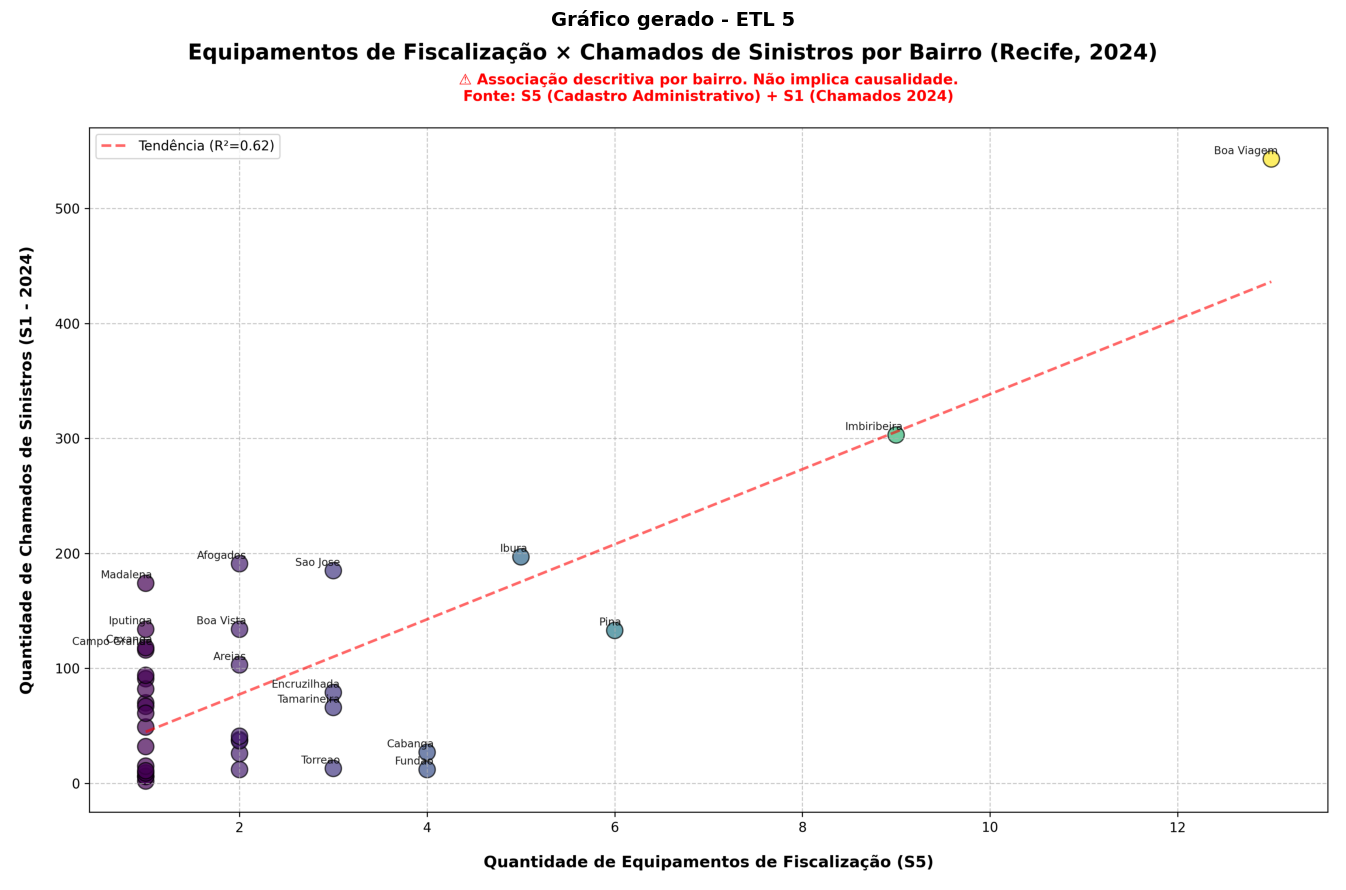

✅ Gráfico exibido com sucesso! Tamanho: (4164, 2656)


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# Carregar e exibir o gráfico que já foi salvo
caminho_grafico = "dados/tratados/dispersao_equipamentos_vs_chamados.png"
img = Image.open(caminho_grafico)

plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.axis('off')  # Remove os eixos da figura de exibição
plt.title("Gráfico gerado - ETL 5", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"✅ Gráfico exibido com sucesso! Tamanho: {img.size}")

In [ ]:
import pandas as pd
import json
import os
from datetime import datetime

# ============================================================
# PASSO 7 — RELATÓRIO DE QUALIDADE E CONCLUSÕES (ETL 5)
# ============================================================
print("="*70)
print("📋 PASSO 7: RELATÓRIO DE QUALIDADE E CONCLUSÕES")
print("="*70)

# 1. Carregar dados brutos e tratados para calcular métricas
caminho_bruto = "dados/brutos/equipamentos_s5_bruto.csv"
caminho_tratado = "dados/tratados/equipamentos_s5_tratado.csv"

df_raw = pd.read_csv(caminho_bruto, sep=';', dtype=str, encoding="utf-8")
df_tratado = pd.read_csv(caminho_tratado)

# Carregar log de extração (se existir)
log_extracao = {}
if os.path.exists("logs/extracao_s5.json"):
    with open("logs/extracao_s5.json", "r", encoding="utf-8") as f:
        log_extracao = json.load(f)

# 2. Calcular métricas de qualidade (convertendo para tipos nativos do Python)
linhas_lidas = int(len(df_raw))
linhas_com_coord_valida = int(df_tratado['coord_valida'].sum())
linhas_sem_coord_valida = int((~df_tratado['coord_valida']).sum())
linhas_carregadas = int(len(df_tratado))

# Nulos nos campos essenciais
nulos_id = int(df_tratado['id_equipamento'].isna().sum())
nulos_tipo = int(df_tratado['tipo_equipamento'].isna().sum())
nulos_local = int(df_tratado['local_instalacao'].isna().sum())
nulos_lat = int(df_tratado['latitude'].isna().sum())
nulos_lon = int(df_tratado['longitude'].isna().sum())

# Percentuais
pct_sem_geo = float((linhas_sem_coord_valida / linhas_lidas) * 100)
pct_nulos_id = float((nulos_id / linhas_lidas) * 100)
pct_nulos_local = float((nulos_local / linhas_lidas) * 100)
taxa_retention = float((linhas_carregadas / linhas_lidas) * 100)

# 3. Criar tabela de qualidade (formato exigido pelo enunciado)
tabela_qualidade = pd.DataFrame({
    "Métrica": [
        "Linhas lidas (bruto)",
        "Linhas rejeitadas (coord. inválidas)",
        "Linhas corrigidas (formatação)",
        "Linhas carregadas (dim_equipamento)",
        "Percentual sem geolocalização",
        "Taxa de retenção"
    ],
    "Valor": [
        linhas_lidas,
        linhas_sem_coord_valida,
        0,  # Apenas padronização, sem rejeição por formatação
        linhas_carregadas,
        f"{pct_sem_geo:.2f}%",
        f"{taxa_retention:.2f}%"
    ]
})

tabela_nulos = pd.DataFrame({
    "Campo Essencial": [
        "identificacao_equipamento",
        "tipo_equipamento",
        "local_instalacao",
        "latitude",
        "longitude"
    ],
    "Nulos": [nulos_id, nulos_tipo, nulos_local, nulos_lat, nulos_lon],
    "Percentual": [
        f"{pct_nulos_id:.2f}%",
        "0.00%",
        f"{pct_nulos_local:.2f}%",
        f"{pct_sem_geo:.2f}%",
        f"{pct_sem_geo:.2f}%"
    ]
})

# 4. Exibir tabelas no Colab
print("\n📊 TABELA DE QUALIDADE — ETL 5")
print("-" * 60)
for _, row in tabela_qualidade.iterrows():
    print(f"{row['Métrica']:<40} | {row['Valor']}")
print("-" * 60)

print("\n📊 NULOS POR CAMPO ESSENCIAL")
print("-" * 60)
for _, row in tabela_nulos.iterrows():
    print(f"{row['Campo Essencial']:<40} | {row['Nulos']} nulos ({row['Percentual']})")
print("-" * 60)

# 5. Salvar relatórios em CSV e JSON
tabela_qualidade.to_csv("dados/tratados/tabela_qualidade_s5.csv", index=False, encoding="utf-8")
tabela_nulos.to_csv("dados/tratados/tabela_nulos_s5.csv", index=False, encoding="utf-8")

relatorio_json = {
    "etl": "S5_Equipamentos_Fiscalizacao",
    "data_geracao": datetime.now().isoformat(),
    "fonte_dados": {
        "dataset": "Equipamentos de Monitoramento e Fiscalização de Trânsito",
        "resource_id": log_extracao.get('resource_id', 'N/A'),
        "url_origem": log_extracao.get('url_origem', 'N/A'),
        "data_extracao": log_extracao.get('data_hora_extracao', 'N/A'),
        "sha256": log_extracao.get('sha256', 'N/A')
    },
    "resumo_qualidade": {
        "linhas_lidas_bruto": linhas_lidas,
        "linhas_rejeitadas_coord_invalida": linhas_sem_coord_valida,
        "linhas_carregadas_dim_equipamento": linhas_carregadas,
        "percentual_sem_geolocalizacao": pct_sem_geo,
        "taxa_retention": taxa_retention
    },
    "taxa_nulos_campos_essenciais": {
        "identificacao_equipamento": {"nulos": nulos_id, "percentual": pct_nulos_id},
        "tipo_equipamento": {"nulos": nulos_tipo, "percentual": 0.0},
        "local_instalacao": {"nulos": nulos_local, "percentual": pct_nulos_local},
        "latitude": {"nulos": nulos_lat, "percentual": pct_sem_geo},
        "longitude": {"nulos": nulos_lon, "percentual": pct_sem_geo}
    }
}

with open("logs/relatorio_qualidade_s5.json", "w", encoding="utf-8") as f:
    json.dump(relatorio_json, f, indent=4, ensure_ascii=False)

print("\n✅ Tabelas de qualidade salvas em: dados/tratados/tabela_qualidade_s5.csv")
print("✅ Relatório JSON salvo em: logs/relatorio_qualidade_s5.json")

# 6. Conclusões e Cuidados Analíticos (Texto para o Relatório Final)
print("\n" + "="*70)
print("📝 CONCLUSÕES E CUIDADOS ANALÍTICOS (Para o Relatório Final)")
print("="*70)
print("""
✅ PONTOS FORTES DOS DADOS:
   • 100% dos registros possuem coordenadas válidas dentro do Recife.
   • 100% dos equipamentos possuem identificador único.
   • Integração espacial com bairros foi 100% bem-sucedida (87/87).
   • Dados extraídos via API CKAN com rastreabilidade completa (SHA256).

⚠️ LIMITAÇÕES E CUIDADOS (NÃO IGNORAR NO RELATÓRIO):

   1. DADOS CADASTRAIS ≠ DADOS OPERACIONAIS
      - O registro indica que o equipamento existe no sistema administrativo,
        mas não garante que estava em funcionamento na data dos sinistros.

   2. NÃO HÁ RELAÇÃO CAUSAL COMPROVADA
      - A presença de equipamentos NÃO prova redução de sinistros.
      - Seria necessário: histórico de instalação, exposição ao tráfego,
        e desenho quasi-experimental (antes/depois).

   3. VERSÃO DO CADASTRO ≠ DATA DE INSTALAÇÃO
      - A data de extração (2026) não é a data de instalação dos equipamentos.
      - Alguns equipamentos podem ter sido instalados após os sinistros de 2024.

   4. COBERTURA DESIGUAL
      - Bairros como Boa Viagem (13 equipamentos) têm mais fiscalização que
        bairros periféricos. Isso pode refletir priorização administrativa,
        não necessariamente maior risco viário.

   5. TIPO ÚNICO DE EQUIPAMENTO
      - Todos os 87 registros são do tipo "Fixo". Não há radares móveis,
        lombadas eletrônicas ou outros tipos neste recurso específico.

📌 RECOMENDAÇÕES PARA O DASHBOARD:
   • No gráfico de dispersão, incluir subtítulo: "Associação descritiva por
     bairro. Não implica causalidade."

   • Ao integrar com chamados (ETL 1), AGREGAR por bairro antes do join.
     Nunca fazer join linha-a-linha (equipamento × chamado) para evitar
     multiplicação artificial de registros.

   • Explicitar no relatório final: "Os dados representam o cadastro
     administrativo na data da extração, não a situação operacional em 2024."
""")

print("="*70)
print("🎉 ETL 5 CONCLUÍDO COM SUCESSO!")
print("="*70)

📋 PASSO 7: RELATÓRIO DE QUALIDADE E CONCLUSÕES

📊 TABELA DE QUALIDADE — ETL 5
------------------------------------------------------------
Linhas lidas (bruto)                     | 87
Linhas rejeitadas (coord. inválidas)     | 0
Linhas corrigidas (formatação)           | 0
Linhas carregadas (dim_equipamento)      | 87
Percentual sem geolocalização            | 0.00%
Taxa de retenção                         | 100.00%
------------------------------------------------------------

📊 NULOS POR CAMPO ESSENCIAL
------------------------------------------------------------
identificacao_equipamento                | 0 nulos (0.00%)
tipo_equipamento                         | 0 nulos (0.00%)
local_instalacao                         | 0 nulos (0.00%)
latitude                                 | 0 nulos (0.00%)
longitude                                | 0 nulos (0.00%)
------------------------------------------------------------

✅ Tabelas de qualidade salvas em: dados/tratados/tabela_qualidade_s5.cs

In [ ]:
from google.colab import drive
import shutil
import os

print("🔄 Iniciando backup de segurança para o Google Drive...")

# 1. Montar o Google Drive (vai pedir permissão, clique em "Allow")
drive.mount('/content/drive')

# 2. Definir pasta de backup no seu Drive
backup_dir = "/content/drive/MyDrive/Backup_ETL5_Recife"
os.makedirs(backup_dir, exist_ok=True)

# 3. Copiar as pastas 'dados' e 'logs'
if os.path.exists("dados"):
    shutil.copytree("dados", os.path.join(backup_dir, "dados"), dirs_exist_ok=True)
    print("✅ Pasta 'dados' (brutos, tratados e geo) copiada com sucesso!")
else:
    print("⚠️ Pasta 'dados' não encontrada.")

if os.path.exists("logs"):
    shutil.copytree("logs", os.path.join(backup_dir, "logs"), dirs_exist_ok=True)
    print("✅ Pasta 'logs' (JSONs e históricos) copiada com sucesso!")
else:
    print("⚠️ Pasta 'logs' não encontrada.")

print(f"\n🎉 BACKUP CONCLUÍDO! Seus arquivos estão 100% seguros em:")
print(f"📁 {backup_dir}")
print("Você pode fechar o Colab tranquilamente agora.")

🔄 Iniciando backup de segurança para o Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Pasta 'dados' (brutos, tratados e geo) copiada com sucesso!
✅ Pasta 'logs' (JSONs e históricos) copiada com sucesso!

🎉 BACKUP CONCLUÍDO! Seus arquivos estão 100% seguros em:
📁 /content/drive/MyDrive/Backup_ETL5_Recife
Você pode fechar o Colab tranquilamente agora.


In [ ]:
from google.colab import drive
import shutil
import os

print("🔄 Iniciando restauração do backup do Google Drive...")

# 1. Montar o Google Drive (se já não estiver montado)
drive.mount('/content/drive')

# 2. Definir caminhos de origem (backup) e destino (Colab)
backup_dir = "/content/drive/MyDrive/Backup_ETL5_Recife"
colab_dir = "/content"

# 3. Restaurar as pastas 'dados' e 'logs'
if os.path.exists(backup_dir):
    # Restaurar pasta 'dados'
    if os.path.exists(os.path.join(backup_dir, "dados")):
        shutil.copytree(os.path.join(backup_dir, "dados"), os.path.join(colab_dir, "dados"), dirs_exist_ok=True)
        print("✅ Pasta 'dados' restaurada com sucesso!")

    # Restaurar pasta 'logs'
    if os.path.exists(os.path.join(backup_dir, "logs")):
        shutil.copytree(os.path.join(backup_dir, "logs"), os.path.join(colab_dir, "logs"), dirs_exist_ok=True)
        print("✅ Pasta 'logs' restaurada com sucesso!")

    print("\n🎉 RESTAURAÇÃO CONCLUÍDA! Seu ambiente está exatamente como você deixou.")
else:
    print("❌ ERRO: Pasta de backup não encontrada no Google Drive.")

🔄 Iniciando restauração do backup do Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Pasta 'dados' restaurada com sucesso!
✅ Pasta 'logs' restaurada com sucesso!

🎉 RESTAURAÇÃO CONCLUÍDA! Seu ambiente está exatamente como você deixou.
